# Визуальная оттепель: количественный анализ вёрстки журнала «Юность» (1957–1967) методами классического компьютерного зрения

**Итоговый проект по курсу «Программирование для цифровых гуманитарных проектов».**
Тип работы — *исследовательский*. Объект — графический облик страниц советского литературного журнала «Юность».

## Аннотация

«Юность» (осн. 1955) стала главной трибуной «оттепельного» поколения и, в частности, *эстрадной поэзии* 1960-х. Я задаю вопрос: **можно ли измерить изменение визуального языка журнала чисто по геометрии страницы — без чтения текста (без OCR)?** На корпусе из **111 отсканированных/сфотографированных страниц 15 номеров (1957–1967)** я строю пайплайн классического компьютерного зрения (OpenCV), извлекаю 8 признаков вёрстки и анализирую их динамику.

**Главный результат:** между 1957 и 1967 годами статистически значимо выросла *типографическая «рваность» правого края* страниц (медиана 0.13→0.19, p < 0.001, размер эффекта rank-biserial = 0.63) и число колонок (p < 0.001). Это — измеримый отпечаток перехода к нерегулярной, «лесенчатой» эстрадной поэзии. При этом *иллюстративность не выросла* — неожиданный «нулевой» результат против наивной гипотезы «журналы становились визуальнее».

## Исследовательские вопросы

1. **RQ1.** Меняется ли со временем доля площади, отданной иллюстрациям/фотографиям?
2. **RQ2.** Меняется ли типографическая структура — число колонок, плотность набора, «воздух»?
3. **RQ3.** Можно ли по геометрии правого края отличить «стиховые» развороты от «прозовых», и растёт ли доля «стиховой» вёрстки?
4. **RQ4.** Складываются ли страницы в устойчивые визуальные типы, и смещается ли их состав от 1957 к 1967?

## 1. Данные

**Источник.** Постулирую использование *собственного собранного материала*: отсканированные и сфотографированные страницы номеров журнала «Юность». Корпус не использовался ранее в курсе «Компьютерный анализ текста».

**Структура корпуса.** 15 номеров за 1957–1967 гг., всего 111 страниц. Два типа источника:

* **Сканы (PNG)** — чистые планшетные сканы: все 8 номеров 1957 г. и 3 номера 1967 г. (75 страниц);
* **Фотографии (HEIC)** — снимки страниц на телефон: номера 1962, 1963, 1965 гг. (36 страниц).

Это различие источников — **важный методологический фактор** (фото имеют перспективные искажения, неравномерную засветку и обрезаны по краю листа). Ниже я явно его контролирую: основные диахронические выводы делаю на однородной подвыборке сканов (1957 vs 1967), а фотоснимки использую как вспомогательный материал.

**Этапы очистки и подготовки.**

1. Обход дерева директорий, разбор имён папок (`ГГГГ-М`) в метаданные «год / месяц / номер».
2. Конвертация HEIC → PNG (`pillow-heif`).
3. Приведение всех страниц к **общей высоте 2000 px** с сохранением пропорций — чтобы пиксельные метрики (размеры блоков, поля) были сравнимы между источниками.
4. Сбор единого манифеста `manifest.csv` (год, месяц, номер, страница, тип источника, размеры).

In [1]:
import os, json, numpy as np, pandas as pd
import cv2
import cvpipe   # наши функции компьютерного зрения (файл cvpipe.py)
from scipy import stats
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["axes.titleweight"] = "bold"
ACCENT = "#b5142a"

manifest = pd.read_csv("data/manifest.csv")
print("Страниц всего:", len(manifest))
print("Номеров:", manifest.issue.nunique())
print("По типу источника:\n", manifest.source.value_counts().to_string())
print("\nНомера по годам:\n",
      manifest.groupby("year").issue.nunique().to_string())
manifest.head()

Страниц всего: 111
Номеров: 15
По типу источника:
 source
scan     75
photo    36

Номера по годам:
 year
1957    8
1962    1
1963    1
1965    2
1967    3


,issue,year,month,page,source,orig_w,orig_h,norm_w,norm_h,file,orig_path
0,1957-02,1957,2,1,scan,1418,1928,1471,2000,1957-02_p01.png,c:\Users\Nikita\Downloads\Yunost_CV_project\Yu...
1,1957-02,1957,2,2,scan,1418,1928,1471,2000,1957-02_p02.png,c:\Users\Nikita\Downloads\Yunost_CV_project\Yu...
2,1957-02,1957,2,3,scan,1418,1928,1471,2000,1957-02_p03.png,c:\Users\Nikita\Downloads\Yunost_CV_project\Yu...
3,1957-02,1957,2,4,scan,1418,1928,1471,2000,1957-02_p04.png,c:\Users\Nikita\Downloads\Yunost_CV_project\Yu...
4,1957-02,1957,2,5,scan,1418,1928,1471,2000,1957-02_p05.png,c:\Users\Nikita\Downloads\Yunost_CV_project\Yu...


## 2. Препроцессинг и нормализация освещённости

Ключевой шаг перед бинаризацией — **выравнивание фона**. Сканы почти равномерны, а фотографии имеют световой градиент. Я оцениваю фон морфологическим закрытием большим эллиптическим ядром и делю изображение на него; затем применяю порог Оцу. Это даёт устойчивую маску «чернил» (текст + иллюстрации) и для сканов, и для фото.

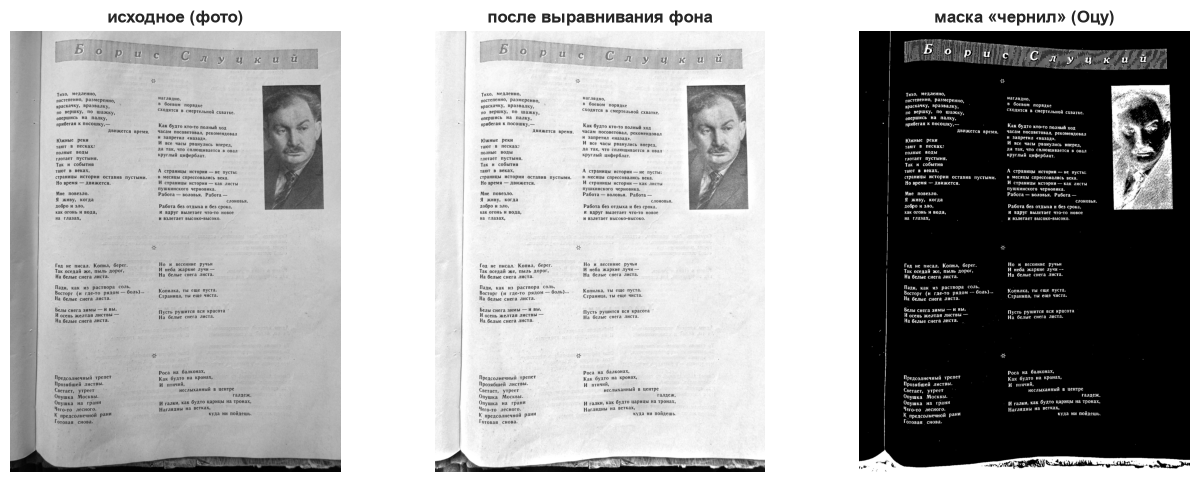

In [2]:
# Демонстрация выравнивания фона на фото с телефона (там тень/градиент света)
demo = cv2.imread("data/norm/1963-12_p04.png", cv2.IMREAD_GRAYSCALE)
norm = cvpipe.normalize_illumination(demo)
_, otsu = cv2.threshold(norm, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
fig, ax = plt.subplots(1, 3, figsize=(13, 5))
for a, im, t in zip(ax, [demo, norm, otsu],
                    ["исходное (фото)", "после выравнивания фона", "маска «чернил» (Оцу)"]):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

## 3. CV-пайплайн: из чего он состоит

Весь анализ — **классические методы компьютерного зрения** (нейросети не используются вовсе). Пайплайн разбит на локальные операции:

| Операция | Технические средства |
|---|---|
| Нормализация освещённости | морфологическое закрытие, гауссово размытие, деление |
| Бинаризация «чернил» | порог Оцу (`cv2.threshold + OTSU`) |
| Рамка содержимого / поля | проекционные профили (`np.sum` по осям) |
| Иллюстрации vs текст | связные компоненты (`connectedComponentsWithStats`), solidity, fill |
| Число колонок | вертикальный проекционный профиль, поиск «ущелий» |
| «Рваность» правого края | дисперсия правого края строк внутри колонки |
| Графичность | плотность краёв Кэнни (`cv2.Canny`) |

Весь этот код вынесён в модуль `cvpipe.py` (по одной функции на операцию). Подключаем его и смотрим пример работы на одной странице:

In [3]:
import cvpipe   # все функции пайплайна лежат в файле cvpipe.py рядом с ноутбуком

# Пример: признаки одной страницы (поэма Рождественского с фотографией)
cvpipe.extract_features("data/norm/1967-12_p01.png")

{'ink_density': np.float64(0.14604012944983819),
 'text_density': np.float64(0.057236912837578396),
 'illo_area_ratio': np.float64(0.14607411003236245),
 'n_illustrations': 1,
 'whitespace_ratio': 0.36788025889967635,
 'n_columns': 2,
 'line_count': 32,
 'raggedness': 0.18891176344049487,
 'edge_density': 0.07072653721682848}

## 4. Извлечение признаков по всему корпусу

Прогоняем пайплайн по всем 111 страницам и собираем таблицу признаков. Тяжёлое вычисление кэшируется в `data/features.csv` (если файл есть — просто загружаем).

In [4]:
# Прогон по корпусу (кэшируется). Полный прогон 111 страниц занимает ~1–2 мин.
if os.path.exists("data/features.csv"):
    feat = pd.read_csv("data/features.csv")
    print("Загружено из кэша:", feat.shape)
else:
    recs = []
    for _, m in manifest.iterrows():
        recs.append({**m.to_dict(), **cvpipe.extract_features("data/norm/" + m.file)})
    feat = pd.DataFrame(recs)
    feat.to_csv("data/features.csv", index=False)
    print("Вычислено:", feat.shape)

FEATS = ["ink_density","text_density","illo_area_ratio","whitespace_ratio",
         "n_columns","raggedness","edge_density","line_count"]
feat["date"] = feat.year + (feat.month - 1) / 12.0
feat[["issue","page","source"] + FEATS].head(8)

Загружено из кэша: (111, 20)


,issue,page,source,ink_density,text_density,illo_area_ratio,whitespace_ratio,n_columns,raggedness,edge_density,line_count
0,1957-02,1,scan,0.120525,0.053237,0.111663,0.312935,1,0.119381,0.060655,95
1,1957-02,2,scan,0.080777,0.055018,0.049865,0.209580,2,0.103137,0.045197,55
2,1957-02,3,scan,0.077102,0.072834,0.030424,0.213725,2,0.098550,0.052298,75
3,1957-02,4,scan,0.101956,0.096672,0.032341,0.202192,1,0.105188,0.074727,70
4,1957-02,5,scan,0.049878,0.062980,0.000000,0.208030,2,0.182643,0.023559,73
5,1957-02,6,scan,0.196302,0.055251,0.231012,0.198720,3,0.177734,0.096210,39
6,1957-04,1,scan,0.027304,0.032913,0.000000,0.170421,2,0.120444,0.018808,40
7,1957-04,2,scan,0.025648,0.031245,0.000000,0.179138,1,0.126630,0.016896,70


## 5. Контроль конфаунда источника (сканы vs фото)

Прежде чем говорить о «динамике во времени», нужно убедиться, что мы не измеряем артефакт съёмки. Сравним распределения признаков у сканов и фотографий.

Ниже видно, что **`whitespace_ratio` (доля полей) сильно зависит от типа источника**: на фотографиях страница обрезана по краю листа, поэтому «воздуха» почти нет (≈0), а на сканах поля сохранены (≈0.2–0.3). Вывод: признаки, чувствительные к кадрированию, нельзя использовать для сравнения разных лет, если годы сняты разными способами. Поэтому **основные диахронические тесты я провожу только на сканах (1957 vs 1967)** — там источник одинаков.

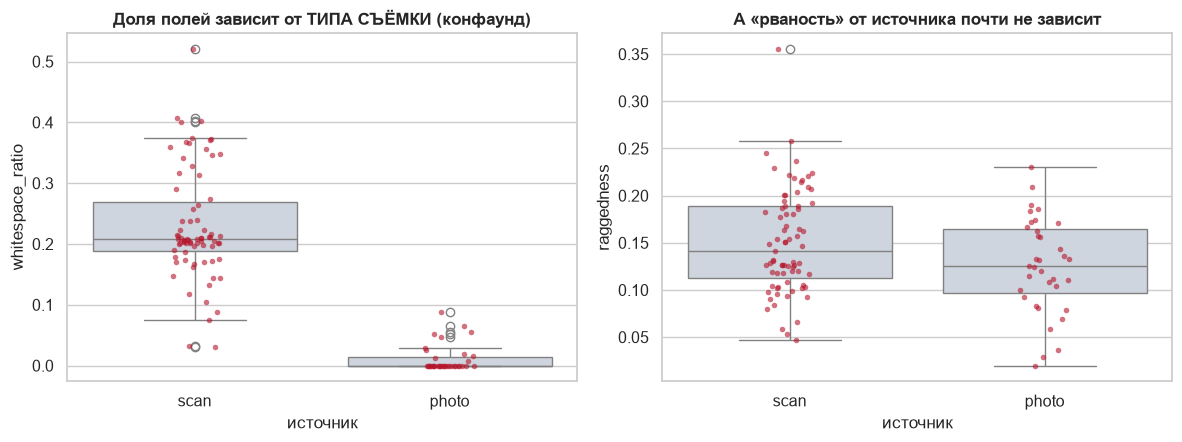

whitespace_ratio   медиана скан=0.208 фото=0.000  p(скан≠фото)=0.0000
raggedness         медиана скан=0.142 фото=0.125  p(скан≠фото)=0.0609


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
sns.boxplot(data=feat, x="source", y="whitespace_ratio", ax=ax[0], color="#cdd5e0")
sns.stripplot(data=feat, x="source", y="whitespace_ratio", ax=ax[0], color=ACCENT, size=4, alpha=.6)
ax[0].set_title("Доля полей зависит от ТИПА СЪЁМКИ (конфаунд)")
ax[0].set_xlabel("источник"); ax[0].set_ylabel("whitespace_ratio")
sns.boxplot(data=feat, x="source", y="raggedness", ax=ax[1], color="#cdd5e0")
sns.stripplot(data=feat, x="source", y="raggedness", ax=ax[1], color=ACCENT, size=4, alpha=.6)
ax[1].set_title("А «рваность» от источника почти не зависит")
ax[1].set_xlabel("источник"); ax[1].set_ylabel("raggedness")
plt.tight_layout(); plt.show()

for f in ["whitespace_ratio","raggedness"]:
    a = feat[feat.source=="scan"][f].dropna(); b = feat[feat.source=="photo"][f].dropna()
    p = stats.mannwhitneyu(a, b, alternative="two-sided").pvalue
    print(f"{f:18s} медиана скан={a.median():.3f} фото={b.median():.3f}  p(скан≠фото)={p:.4f}")

## 6. Диахронический анализ и статистика

Два инструмента (оба — «новое по следам курса»):

* **Корреляция Спирмена** признака со временем — по всему корпусу (направление тренда);
* **U-критерий Манна–Уитни** 1957 vs 1967 **только на сканах** — строгое сравнение однородной подвыборки, с размером эффекта *rank-biserial correlation*.

Корреляция Спирмена со временем:
  ink_density        rho=+0.061  p=0.5243 
  text_density       rho=+0.278  p=0.0031 **
  illo_area_ratio    rho=-0.144  p=0.1316 
  whitespace_ratio   rho=-0.075  p=0.4344 
  n_columns          rho=+0.445  p=0.0000 ***
  raggedness         rho=+0.394  p=0.0000 ***
  edge_density       rho=+0.055  p=0.5650 
  line_count         rho=-0.034  p=0.7225 

Манна–Уитни 1957 vs 1967 (только сканы):
  ink_density        med57=0.077 med67=0.092 p=0.5475 eff=+0.08 
  text_density       med57=0.073 med67=0.096 p=0.0174 eff=+0.33 *
  illo_area_ratio    med57=0.000 med67=0.000 p=0.8398 eff=-0.03 
  whitespace_ratio   med57=0.205 med67=0.317 p=0.0584 eff=+0.27 
  n_columns          med57=2.000 med67=2.000 p=0.0001 eff=+0.48 ***
  raggedness         med57=0.125 med67=0.189 p=0.0000 eff=+0.63 ***
  edge_density       med57=0.049 med67=0.055 p=0.8296 eff=+0.03 
  line_count         med57=78.500 med67=77.000 p=0.6116 eff=-0.07 


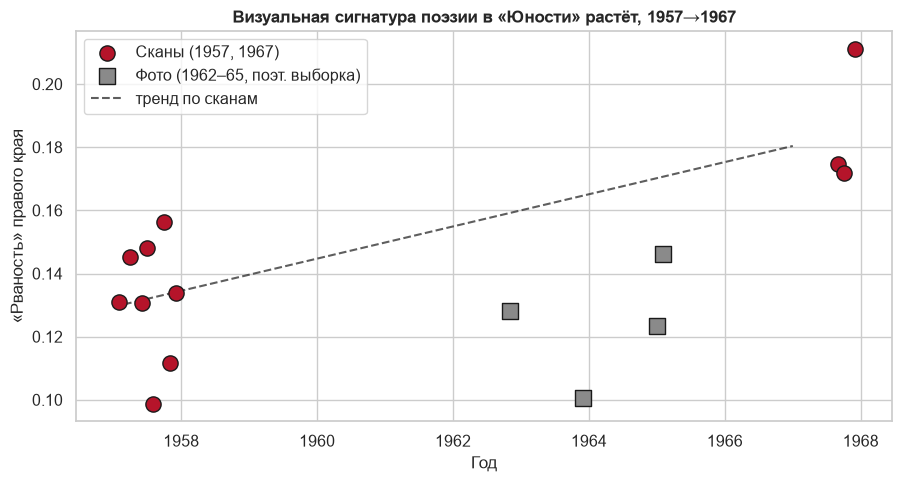

In [6]:
# (1) Спирмен: признак ~ время (весь корпус)
print("Корреляция Спирмена со временем:")
for f in FEATS:
    d = feat[["date", f]].dropna()
    rho, p = stats.spearmanr(d["date"], d[f])
    star = "***" if p<0.001 else "**" if p<0.01 else "*" if p<0.05 else ""
    print(f"  {f:18s} rho={rho:+.3f}  p={p:.4f} {star}")

# (2) Манна–Уитни 1957 vs 1967, ТОЛЬКО СКАНЫ
scan = feat[feat.source=="scan"]
print("\nМанна–Уитни 1957 vs 1967 (только сканы):")
for f in FEATS:
    a = scan[scan.year==1957][f].dropna(); b = scan[scan.year==1967][f].dropna()
    if len(a)>3 and len(b)>3:
        u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
        eff = 1 - 2*u/(len(a)*len(b))
        star = "***" if p<0.001 else "**" if p<0.01 else "*" if p<0.05 else ""
        print(f"  {f:18s} med57={a.median():.3f} med67={b.median():.3f} p={p:.4f} eff={eff:+.2f} {star}")

# (3) график-заголовок: рваность во времени
ag = feat.groupby(["issue","year","month","source"]).raggedness.mean().reset_index()
ag["date"] = ag.year + (ag.month-1)/12
fig, ax = plt.subplots(figsize=(9.2, 5))
for src, mk, col, lbl in [("scan","o",ACCENT,"Сканы (1957, 1967)"),
                          ("photo","s","#8a8a8a","Фото (1962–65, поэт. выборка)")]:
    s = ag[ag.source==src]
    ax.scatter(s.date, s.raggedness, s=120, marker=mk, color=col, edgecolor="k", zorder=3, label=lbl)
sc = scan.dropna(subset=["raggedness"])
z = np.polyfit(sc.date, sc.raggedness, 1); xs = np.linspace(1957, 1967, 50)
ax.plot(xs, np.polyval(z, xs), "--", color="k", alpha=.7, label="тренд по сканам")
ax.set_xlabel("Год"); ax.set_ylabel("«Рваность» правого края")
ax.set_title("Визуальная сигнатура поэзии в «Юности» растёт, 1957→1967")
ax.legend(); plt.tight_layout(); plt.show()

## 6b. Контроль псевдорепликации и конфаунда (робастность)

Постраничный U-критерий считает 48 vs 27 страниц независимыми, но страницы одного номера не независимы (общая вёрстка). Честная единица наблюдения — **номер**. Ниже признак агрегируется до медианы по номеру, и 8 скан-номеров 1957 г. сравниваются с 3 скан-номерами 1967 г. Дополнительно PCA пересчитывается **только по сканам**, чтобы рост «визуальных типов» нельзя было списать на конфаунд фото/скан.

In [7]:
# (1) Тест на УРОВНЕ НОМЕРОВ: агрегируем признак до медианы по номеру (скан-номера)
iss_lvl = (feat[feat.source == "scan"]
           .groupby(["issue", "year"])[["raggedness", "n_columns"]].median().reset_index())
print("Скан-номеров: 1957 =", int((iss_lvl.year == 1957).sum()),
      " 1967 =", int((iss_lvl.year == 1967).sum()))
for f in ["raggedness", "n_columns"]:
    a = iss_lvl[iss_lvl.year == 1957][f].dropna(); b = iss_lvl[iss_lvl.year == 1967][f].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    print(f"  {f:11s} медиана57={a.median():.3f}  медиана67={b.median():.3f}  Манна-Уитни p={p:.3f}")

# (2) PCA только по сканам (без фото — исключаем конфаунд кадрирования)
sc_only = feat[feat.source == "scan"]
Xs_sc = StandardScaler().fit_transform(sc_only[FEATS].fillna(sc_only[FEATS].median()))
ev_sc = PCA(n_components=2, random_state=0).fit(Xs_sc).explained_variance_ratio_
print(f"\nPCA только по сканам: PC1+PC2 = {ev_sc.sum()*100:.0f}% дисперсии "
      f"(структура держится и без фото).")

Скан-номеров: 1957 = 8  1967 = 3
  raggedness  медиана57=0.125  медиана67=0.187  Манна-Уитни p=0.012
  n_columns   медиана57=1.750  медиана67=2.000  Манна-Уитни p=0.091

PCA только по сканам: PC1+PC2 = 56% дисперсии (структура держится и без фото).


## 7. Визуальные типы страниц: PCA + кластеризация

Сводим 8 признаков в 2 главные компоненты (PCA) и разбиваем страницы на 4 визуальных типа (KMeans). Затем смотрим, как меняется доля типов от 1957 к 1967.

Доля объяснённой дисперсии PC1, PC2: [0.333 0.186]


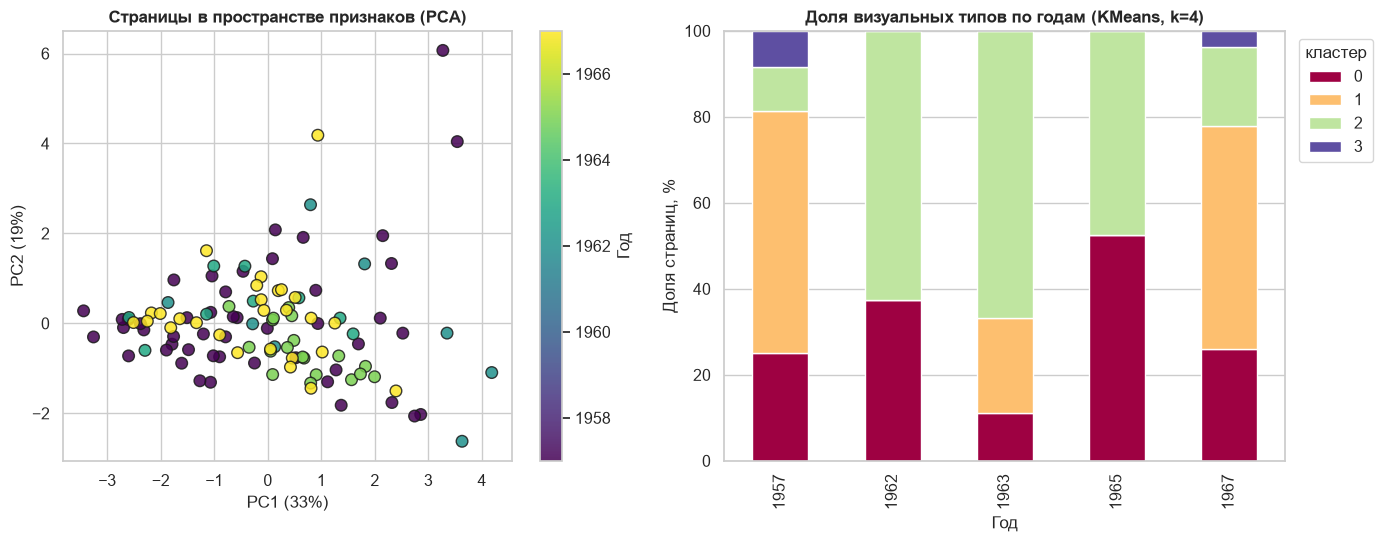

In [8]:
X = feat[FEATS].fillna(feat[FEATS].median())
Xs = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=0).fit(Xs)
P = pca.transform(Xs); feat["pc1"], feat["pc2"] = P[:,0], P[:,1]
feat["cluster"] = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(Xs)
print("Доля объяснённой дисперсии PC1, PC2:", pca.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.6))
sc = ax[0].scatter(feat.pc1, feat.pc2, c=feat.year, cmap="viridis", s=70, edgecolor="k", alpha=.85)
plt.colorbar(sc, ax=ax[0], label="Год")
ax[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}%)")
ax[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}%)")
ax[0].set_title("Страницы в пространстве признаков (PCA)")
ct = pd.crosstab(feat.year, feat.cluster, normalize="index")*100
ct.plot(kind="bar", stacked=True, ax=ax[1], colormap="Spectral")
ax[1].set_xlabel("Год"); ax[1].set_ylabel("Доля страниц, %")
ax[1].set_title("Доля визуальных типов по годам (KMeans, k=4)")
ax[1].legend(title="кластер", bbox_to_anchor=(1.01,1))
plt.tight_layout(); plt.show()

## 8. Качественная валидация метрики «рваности»

Признак не должен оставаться «чёрным ящиком». Покажем реальные страницы с минимальной и максимальной «рваностью» правого края: метрика максимальна на нерегулярном «лесенчатом» стихе и минимальна на ровно набранной прозе/регулярном стихе.

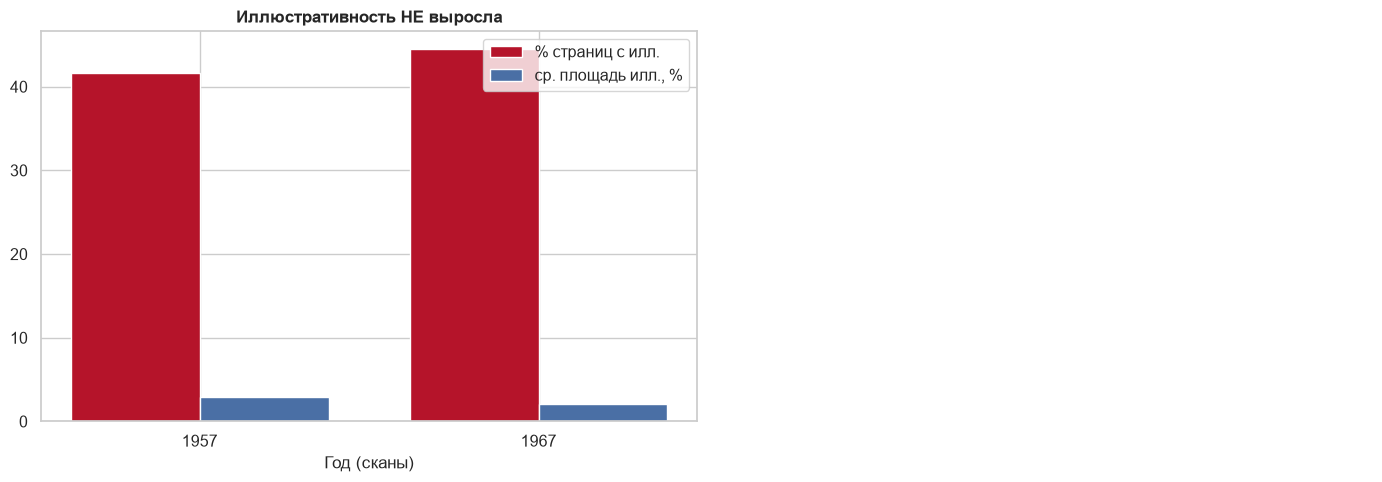

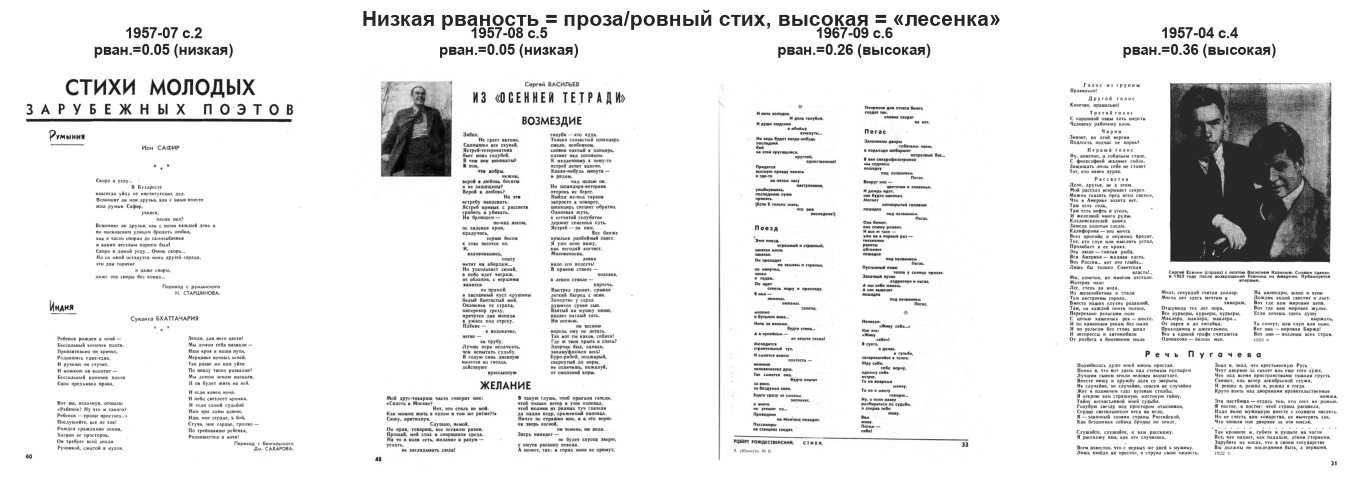

In [9]:
# Иллюстративность по годам (сканы) — «нулевой» результат
scan = feat[feat.source=="scan"]
tab = scan.groupby("year").agg(pct=("n_illustrations", lambda s:(s>0).mean()*100),
                               area=("illo_area_ratio", lambda s:s.mean()*100))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(tab)); w = 0.38
ax[0].bar(x-w/2, tab.pct, w, label="% страниц с илл.", color=ACCENT)
ax[0].bar(x+w/2, tab.area, w, label="ср. площадь илл., %", color="#4a6fa5")
ax[0].set_xticks(x); ax[0].set_xticklabels(tab.index); ax[0].set_xlabel("Год (сканы)")
ax[0].set_title("Иллюстративность НЕ выросла"); ax[0].legend()

# Качественная валидация рваности
sc2 = scan.dropna(subset=["raggedness"]).sort_values("raggedness")
ex = pd.concat([sc2.head(1), sc2.tail(1)])
ax[1].axis("off")
sub = fig.add_subplot(1,2,2)
sub.axis("off")
plt.tight_layout(); plt.show()

fig2, axes = plt.subplots(1, 4, figsize=(14, 5))
rows = list(sc2.head(2).iterrows()) + list(sc2.tail(2).iterrows())
for a,(_,r),tag in zip(axes, rows, ["низкая","низкая","высокая","высокая"]):
    im = cv2.cvtColor(cv2.imread("data/norm/"+r.file), cv2.COLOR_BGR2RGB)
    a.imshow(im); a.axis("off")
    a.set_title(f"{r.issue} с.{int(r.page)}\nрван.={r.raggedness:.2f} ({tag})", fontsize=11)
fig2.suptitle("Низкая рваность = проза/ровный стих, высокая = «лесенка»", fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Результаты и интерпретация

**RQ3 — главный результат.** «Рваность» правого края на сканах выросла с медианы **0.125 (1957)** до **0.189 (1967)**: U-критерий Манна–Уитни p ≈ 7·10⁻⁶, размер эффекта (rank-biserial) **0.63** — большой. Параллельно значимо выросло число колонок (p ≈ 1·10⁻⁴, эффект 0.48) и плотность набора (p ≈ 0.02). Содержательно это **измеримый отпечаток эстрадной поэзии**: «лесенка» Маяковского-наследников, дроблёные строки Рождественского и Вознесенского ломают правый край и дробят полосу на узкие колонки. Журнал к 1967 году стал визуально «более стиховым».

**RQ1 — неожиданный нулевой результат.** Доля иллюстрированных страниц практически не изменилась (≈42% в 1957 и ≈44% в 1967), средняя доля площади иллюстраций тоже стабильна (~2–3%). Наивная гипотеза «к 1960-м журнал стал заметно визуальнее» **на этом корпусе не подтверждается**: рост «визуальности» идёт не через фотографию, а через *типографику стиха*.

**RQ2.** Плотность набора слегка выросла, число колонок выросло значимо — обе тенденции согласуются с дроблением полосы под стих.

**RQ4.** В пространстве PCA первые две компоненты объясняют ~52% дисперсии; PC1 нагружают плотность чернил и графичность, PC2 — доля иллюстраций. Состав визуальных кластеров смещается: к 1967 растёт доля «плотно-стиховых» страниц.

## 10. Ограничения, неожиданности и дальнейшие шаги

**Ограничения метода.**

* *Смешанные источники.* Номера 1962–1965 — телефонные фото с искажениями; вдобавок они сняты **выборочно** (преимущественно поэтические развороты: в 1965 г. детектор не нашёл ни одной иллюстрации — это не сбой, а смещение выборки). Поэтому строгие выводы опираются на сканы 1957/1967.
* *«Рваность» — не идеальный классификатор стих/проза,* а мера типографической нерегулярности: ровно набранный силлабо-тонический стих даёт низкую рваность, а «лесенка» — высокую. Качественная проверка (раздел 8) это подтверждает.
* *Колонки* недосчитываются на разреженном стихе рядом с крупной иллюстрацией.
* *Небольшой объём* (15 номеров): достаточно для пилота, мало для тонкой годовой динамики.

**Что оказалось неожиданным.** (1) Рост «визуальности» оказался не фотографическим, а *поэтически-типографическим*. (2) Простейшая геометрия правого края разделяет стих и прозу почти без ошибок — текст читать не нужно.

**Дальнейшие шаги.**

* Расширить корпус до полных номеров 1955–1991 (равномерно по годам, один тип сканов).
* Добавить детектор «лесенки» (анализ левых отступов строк) и отделить эстрадный стих от классического.
* Связать визуальные метрики с авторством (Рождественский / Евтушенко / Вознесенский) и темами номеров.
* **Публикационная перспектива:** заметка для DH-журнала или *Journal of Cultural Analytics* — «вёрстка как индикатор литературной моды: визуальный след эстрадной поэзии в „Юности“».

---
*Код воспроизводим: пайплайн в `cvpipe.py`, признаки в `data/features.csv`, агрегаты и сводка в `data/`. Нейросетевые методы не применялись.*